In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from shapely.geometry import Point

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette("Blues_d")

RUTA = "/Users/lucasespinosa/Documents/proyecto5-inmobiliario-valencia/data/"
df = pd.read_csv(RUTA + "valencia_sale_idealista18.csv")
print(f"✅ Datos cargados: {df.shape[0]:,} filas")

✅ Datos cargados: 33,622 filas


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from shapely.geometry import Point

# Configuración visual
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette("Blues_d")

# Ruta
RUTA = "/Users/lucasespinosa/Documents/proyecto5-inmobiliario-valencia/data/"

# Cargar datos de anuncios
df = pd.read_csv(RUTA + "valencia_sale_idealista18.csv")

print("✅ Datos cargados")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")
print(f"\nPrecio por m² (€/m²):")
print(f"  Media:   {df['UNITPRICE'].mean():,.0f}")
print(f"  Mediana: {df['UNITPRICE'].median():,.0f}")
print(f"  Mínimo:  {df['UNITPRICE'].min():,.0f}")
print(f"  Máximo:  {df['UNITPRICE'].max():,.0f}")

✅ Datos cargados
Filas: 33,622
Columnas: 41

Precio por m² (€/m²):
  Media:   1,715
  Mediana: 1,531
  Mínimo:  481
  Máximo:  9,422


In [5]:
# ── BLOQUE 2 — Cargar barrios y asignar barrio a cada vivienda ──

barrios = gpd.read_file(RUTA + "valencia_barrios.geojson")
print(f"✅ Barrios cargados: {len(barrios)}")

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df['LONGITUDE'], df['LATITUDE']),
    crs="EPSG:4326"
)
print(f"✅ Anuncios convertidos a GeoDataFrame: {len(gdf):,} puntos")

barrios = barrios.to_crs("EPSG:4326")

gdf_join = gpd.sjoin(gdf, barrios[['LOCATIONID','LOCATIONNAME','geometry']],
                     how='left', predicate='within')

print(f"\n✅ Spatial join completado")
print(f"Anuncios con barrio asignado: {gdf_join['LOCATIONNAME'].notna().sum():,}")
print(f"Anuncios sin barrio asignado: {gdf_join['LOCATIONNAME'].isna().sum():,}")
print(f"\nTop 10 barrios con más anuncios:")
print(gdf_join['LOCATIONNAME'].value_counts().head(10))

✅ Barrios cargados: 73
✅ Anuncios convertidos a GeoDataFrame: 33,622 puntos

✅ Spatial join completado
Anuncios con barrio asignado: 33,580
Anuncios sin barrio asignado: 44

Top 10 barrios con más anuncios:
LOCATIONNAME
Benicalap                    1581
Torrefiel                    1378
Russafa                      1313
Nou Moles                    1294
Arrancapins                  1267
Els Orriols                  1009
El Cabanyal-El Canyamelar     988
Patraix                       962
Sant Francesc                 833
La Raiosa                     748
Name: count, dtype: int64


In [6]:
# ── BLOQUE 3 — Precio de compra promedio por barrio ──

df_barrio = gdf_join[gdf_join['LOCATIONNAME'].notna()].copy()

compra_barrio = df_barrio.groupby('LOCATIONNAME').agg(
    precio_compra_m2 = ('UNITPRICE', 'median'),
    n_anuncios       = ('UNITPRICE', 'count'),
    precio_total_med = ('PRICE', 'median'),
    sup_media        = ('CONSTRUCTEDAREA', 'median')
).reset_index()

compra_barrio = compra_barrio[compra_barrio['n_anuncios'] >= 10].copy()

print(f"✅ Precio de compra calculado: {len(compra_barrio)} barrios")
print(f"\nTop 10 barrios más CAROS (€/m²):")
print(compra_barrio.nlargest(10, 'precio_compra_m2')[
    ['LOCATIONNAME','precio_compra_m2','n_anuncios']].to_string(index=False))
print(f"\nTop 10 barrios más BARATOS (€/m²):")
print(compra_barrio.nsmallest(10, 'precio_compra_m2')[
    ['LOCATIONNAME','precio_compra_m2','n_anuncios']].to_string(index=False))

✅ Precio de compra calculado: 73 barrios

Top 10 barrios más CAROS (€/m²):
    LOCATIONNAME  precio_compra_m2  n_anuncios
El Pla del Remei       3334.166667         636
        La Xerea       2986.725664         355
   Sant Francesc       2915.000000         833
        Gran Vía       2826.351351         584
       Exposició       2760.000000         335
      Penya-Roja       2722.504785         418
          La Seu       2583.801498         250
        Sant Pau       2402.056133         486
      Jaume Roig       2301.612903         234
        Mestalla       2270.622896         486

Top 10 barrios más BARATOS (€/m²):
         LOCATIONNAME  precio_compra_m2  n_anuncios
       Ciutat Fallera        767.619615         304
Fonteta de Sant Lluìs        772.151899         147
             Natzaret        774.420718         214
          Els Orriols        869.565217        1009
        Sant Marcellí        957.142857         377
         Tres Forques        958.745348         584
        

In [7]:
print(dir())

['In', 'Out', 'Point', 'RUTA', '_', '__', '___', '__builtin__', '__builtins__', '__doc__', '__loader__', '__name__', '__package__', '__session__', '__spec__', '_dh', '_i', '_i1', '_i2', '_i3', '_i4', '_i5', '_i6', '_i7', '_ih', '_ii', '_iii', '_oh', 'barrios', 'compra_barrio', 'df', 'df_barrio', 'exit', 'gdf', 'gdf_join', 'get_ipython', 'gpd', 'np', 'open', 'pd', 'plt', 'quit', 'sns']


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from shapely.geometry import Point

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette("Blues_d")

RUTA = "/Users/lucasespinosa/Documents/proyecto5-inmobiliario-valencia/data/"
df = pd.read_csv(RUTA + "valencia_sale_idealista18.csv")
print(f"✅ Datos cargados: {df.shape[0]:,} filas")

✅ Datos cargados: 33,622 filas


In [9]:
barrios = gpd.read_file(RUTA + "valencia_barrios.geojson")
print(f"✅ Barrios cargados: {len(barrios)}")

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df['LONGITUDE'], df['LATITUDE']),
    crs="EPSG:4326"
)
barrios = barrios.to_crs("EPSG:4326")

gdf_join = gpd.sjoin(gdf, barrios[['LOCATIONID','LOCATIONNAME','geometry']],
                     how='left', predicate='within')

print(f"✅ Spatial join completado: {gdf_join['LOCATIONNAME'].notna().sum():,} asignados")

✅ Barrios cargados: 73
✅ Spatial join completado: 33,580 asignados


In [10]:
df_barrio = gdf_join[gdf_join['LOCATIONNAME'].notna()].copy()

compra_barrio = df_barrio.groupby('LOCATIONNAME').agg(
    precio_compra_m2 = ('UNITPRICE', 'median'),
    n_anuncios       = ('UNITPRICE', 'count'),
    precio_total_med = ('PRICE', 'median'),
    sup_media        = ('CONSTRUCTEDAREA', 'median')
).reset_index()

compra_barrio = compra_barrio[compra_barrio['n_anuncios'] >= 10].copy()

print(f"✅ Precio de compra calculado: {len(compra_barrio)} barrios")
print(f"\nTop 10 barrios más CAROS (€/m²):")
print(compra_barrio.nlargest(10, 'precio_compra_m2')[
    ['LOCATIONNAME','precio_compra_m2','n_anuncios']].to_string(index=False))
print(f"\nTop 10 barrios más BARATOS (€/m²):")
print(compra_barrio.nsmallest(10, 'precio_compra_m2')[
    ['LOCATIONNAME','precio_compra_m2','n_anuncios']].to_string(index=False))

✅ Precio de compra calculado: 73 barrios

Top 10 barrios más CAROS (€/m²):
    LOCATIONNAME  precio_compra_m2  n_anuncios
El Pla del Remei       3334.166667         636
        La Xerea       2986.725664         355
   Sant Francesc       2915.000000         833
        Gran Vía       2826.351351         584
       Exposició       2760.000000         335
      Penya-Roja       2722.504785         418
          La Seu       2583.801498         250
        Sant Pau       2402.056133         486
      Jaume Roig       2301.612903         234
        Mestalla       2270.622896         486

Top 10 barrios más BARATOS (€/m²):
         LOCATIONNAME  precio_compra_m2  n_anuncios
       Ciutat Fallera        767.619615         304
Fonteta de Sant Lluìs        772.151899         147
             Natzaret        774.420718         214
          Els Orriols        869.565217        1009
        Sant Marcellí        957.142857         377
         Tres Forques        958.745348         584
        

In [11]:
# ── BLOQUE 4 — Estimación de alquiler por barrio (metodología transparente) ──
# NOTA METODOLÓGICA: No se encontraron datos oficiales de alquiler por barrio
# accesibles al momento del análisis. Se estima el alquiler aplicando el yield
# (rentabilidad) medio documentado para Valencia (~5,9% anual, fuente: informes
# públicos del sector inmobiliario), ajustado según el patrón de mercado conocido:
# los barrios más caros en compra tienden a tener yields más bajos, y los barrios
# más económicos tienden a tener yields más altos. Esta es una estimación
# declarada, no un dato observado.

YIELD_MAX = 7.5   # yield para el barrio más barato
YIELD_MIN = 4.5   # yield para el barrio más caro

precio_min = compra_barrio['precio_compra_m2'].min()
precio_max = compra_barrio['precio_compra_m2'].max()

compra_barrio['factor_precio'] = (compra_barrio['precio_compra_m2'] - precio_min) / (precio_max - precio_min)
compra_barrio['yield_estimado'] = YIELD_MAX - compra_barrio['factor_precio'] * (YIELD_MAX - YIELD_MIN)
compra_barrio['alquiler_m2_mes_est'] = (compra_barrio['precio_compra_m2'] * compra_barrio['yield_estimado'] / 100) / 12

print("✅ Alquiler estimado por barrio")
print(f"\nYield medio resultante: {compra_barrio['yield_estimado'].mean():.2f}%")
print(f"\nMuestra de 10 barrios (precio compra -> yield -> alquiler estimado):")
print(compra_barrio[['LOCATIONNAME','precio_compra_m2','yield_estimado','alquiler_m2_mes_est']]
      .sample(10, random_state=42).to_string(index=False))

✅ Alquiler estimado por barrio

Yield medio resultante: 6.47%

Muestra de 10 barrios (precio compra -> yield -> alquiler estimado):
   LOCATIONNAME  precio_compra_m2  yield_estimado  alquiler_m2_mes_est
      Benicalap       1081.081081        7.133599             6.426666
    Sant Isidre       1137.772857        7.067333             6.700850
     El Calvari       1200.000000        6.994597             6.994597
          Aiora       1385.078777        6.778261             7.823688
       Gran Vía       2826.351351        5.093578            11.996868
  Vara de Quart       1166.666667        7.033560             6.838183
     Camí Reial       1100.000000        7.111485             6.518862
La Creu Coberta       1057.377049        7.161307             6.310168
 Ciutat Fallera        767.619615        7.500000             4.797623
      Nou Moles       1262.828947        6.921157             7.283531


In [12]:
# ── BLOQUE 5 — Cálculo de rentabilidad (yield) por barrio ──

compra_barrio['alquiler_anual_m2'] = compra_barrio['alquiler_m2_mes_est'] * 12
compra_barrio['yield_bruto_pct'] = (compra_barrio['alquiler_anual_m2'] / compra_barrio['precio_compra_m2']) * 100

# Ranking de rentabilidad
ranking = compra_barrio.sort_values('yield_bruto_pct', ascending=False)

print("✅ Rentabilidad calculada\n")
print("TOP 10 barrios MÁS RENTABLES:")
print(ranking.head(10)[['LOCATIONNAME','precio_compra_m2','alquiler_m2_mes_est','yield_bruto_pct']].to_string(index=False))

print("\nTOP 10 barrios MENOS RENTABLES:")
print(ranking.tail(10)[['LOCATIONNAME','precio_compra_m2','alquiler_m2_mes_est','yield_bruto_pct']].to_string(index=False))

print(f"\nYield medio de Valencia (foco): {compra_barrio['yield_bruto_pct'].mean():.2f}%")

✅ Rentabilidad calculada

TOP 10 barrios MÁS RENTABLES:
         LOCATIONNAME  precio_compra_m2  alquiler_m2_mes_est  yield_bruto_pct
       Ciutat Fallera        767.619615             4.797623         7.500000
Fonteta de Sant Lluìs        772.151899             4.822540         7.494702
             Natzaret        774.420718             4.834999         7.492050
          Els Orriols        869.565217             5.348433         7.380837
        Sant Marcellí        957.142857             5.805446         7.278469
         Tres Forques        958.745348             5.813669         7.276596
            Torrefiel        996.031746             6.003592         7.233012
         La Fontsanta       1023.434343             6.141443         7.200982
      La Creu Coberta       1057.377049             6.310168         7.161307
            Benicalap       1081.081081             6.426666         7.133599

TOP 10 barrios MENOS RENTABLES:
    LOCATIONNAME  precio_compra_m2  alquiler_m2_mes_e

In [13]:
# ── BLOQUE 6 — Preparar datos para el modelo de precios ──

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb

# Variables predictoras: características objetivas de la vivienda
FEATURES = ['CONSTRUCTEDAREA', 'ROOMNUMBER', 'BATHNUMBER', 'HASTERRACE',
            'HASLIFT', 'HASAIRCONDITIONING', 'HASPARKINGSPACE',
            'HASSWIMMINGPOOL', 'ISDUPLEX', 'CONSTRUCTIONYEAR',
            'DISTANCE_TO_CITY_CENTER', 'DISTANCE_TO_METRO', 'DISTANCE_TO_BLASCO']

TARGET = 'UNITPRICE'  # precio por m² — lo que queremos predecir

# Dataset limpio: solo filas con barrio asignado y sin nulos en las features
df_modelo = df_barrio[FEATURES + [TARGET, 'LOCATIONNAME']].dropna().copy()

print(f"✅ Dataset preparado: {len(df_modelo):,} viviendas para modelar")
print(f"Features: {len(FEATURES)}")

# Split: 80% entrenamiento, 20% validación (aleatorio porque NO es serie temporal)
X = df_modelo[FEATURES]
y = df_modelo[TARGET]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Entrenamiento: {len(X_train):,} viviendas")
print(f"Validación:    {len(X_val):,} viviendas")

✅ Dataset preparado: 20,395 viviendas para modelar
Features: 13
Entrenamiento: 16,316 viviendas
Validación:    4,079 viviendas


In [14]:
# ── BLOQUE 7 — Entrenar el modelo LightGBM ──

modelo = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=64,
    min_child_samples=20,
    random_state=42,
    verbose=-1
)

modelo.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(50, verbose=False),
               lgb.log_evaluation(100)]
)

print(f"✅ Modelo entrenado — Mejor iteración: {modelo.best_iteration_}")

# Evaluación
y_pred = modelo.predict(X_val)
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print(f"\nMAE:  {mae:,.0f} €/m²")
print(f"RMSE: {rmse:,.0f} €/m²")
print(f"Precio medio real: {y_val.mean():,.0f} €/m²")
print(f"Error relativo (MAE/precio medio): {mae/y_val.mean()*100:.1f}%")

[100]	valid_0's l2: 173239
[200]	valid_0's l2: 157071
[300]	valid_0's l2: 148106
[400]	valid_0's l2: 142954
[500]	valid_0's l2: 139742
✅ Modelo entrenado — Mejor iteración: 500

MAE:  244 €/m²
RMSE: 374 €/m²
Precio medio real: 1,702 €/m²
Error relativo (MAE/precio medio): 14.3%


In [15]:
# ── BLOQUE 8 — Detección de sobre/infravaloración por barrio ──

# Predecir sobre TODO el dataset (no solo validación) para tener cobertura completa
df_modelo['precio_predicho'] = modelo.predict(df_modelo[FEATURES])
df_modelo['diferencia_pct'] = ((df_modelo['UNITPRICE'] - df_modelo['precio_predicho']) 
                                 / df_modelo['precio_predicho']) * 100

# Agregamos por barrio
valoracion_barrio = df_modelo.groupby('LOCATIONNAME').agg(
    precio_real_medio    = ('UNITPRICE', 'median'),
    precio_predicho_medio = ('precio_predicho', 'median'),
    diferencia_pct_media  = ('diferencia_pct', 'median'),
    n_viviendas           = ('UNITPRICE', 'count')
).reset_index()

valoracion_barrio = valoracion_barrio[valoracion_barrio['n_viviendas'] >= 10].copy()

print("✅ Valoración por barrio calculada\n")
print("TOP 10 barrios MÁS SOBREVALORADOS (precio real > lo que justifican sus características):")
print(valoracion_barrio.nlargest(10, 'diferencia_pct_media')[
    ['LOCATIONNAME','precio_real_medio','precio_predicho_medio','diferencia_pct_media']].to_string(index=False))

print("\nTOP 10 barrios MÁS INFRAVALORADOS (oportunidades — precio real < lo esperado):")
print(valoracion_barrio.nsmallest(10, 'diferencia_pct_media')[
    ['LOCATIONNAME','precio_real_medio','precio_predicho_medio','diferencia_pct_media']].to_string(index=False))

✅ Valoración por barrio calculada

TOP 10 barrios MÁS SOBREVALORADOS (precio real > lo que justifican sus características):
LOCATIONNAME  precio_real_medio  precio_predicho_medio  diferencia_pct_media
Nou Campanar        2365.641711            2318.690710              5.494134
    Campanar        1619.402985            1479.692651              5.046086
 La Carrasca        1958.333333            1860.856471              3.629515
Camí de Vera        1898.124098            1896.631872              2.905078
  Benimaclet        1681.818182            1651.478391              2.394404
    La Punta        1450.000000            1421.698734              2.355139
  Penya-Roja        2719.803477            2614.064984              2.309117
     La Llum        1358.620690            1272.461973              2.219255
    Soternes        1293.333333            1283.097370              2.200974
     Russafa        2243.243243            2157.443532              1.882599

TOP 10 barrios MÁS INFRAVALO

In [16]:
# ── BLOQUE 9 — Preparar datos geográficos para el mapa ──

import folium

# Unimos los polígonos geográficos con nuestros cálculos de rentabilidad y valoración
mapa_data = barrios.merge(compra_barrio[['LOCATIONNAME','precio_compra_m2',
                                          'alquiler_m2_mes_est','yield_bruto_pct']],
                          on='LOCATIONNAME', how='left')

mapa_data = mapa_data.merge(valoracion_barrio[['LOCATIONNAME','diferencia_pct_media']],
                            on='LOCATIONNAME', how='left')

print(f"✅ Datos geográficos preparados: {len(mapa_data)} barrios")
print(f"Barrios con datos completos: {mapa_data['yield_bruto_pct'].notna().sum()}")

# Coordenadas del centro de Valencia para centrar el mapa
LAT_CENTRO = 39.4699
LON_CENTRO = -0.3763

print(f"\nRango de yield: {mapa_data['yield_bruto_pct'].min():.1f}% a {mapa_data['yield_bruto_pct'].max():.1f}%")

✅ Datos geográficos preparados: 73 barrios
Barrios con datos completos: 73

Rango de yield: 4.5% a 7.5%


In [17]:
# ── BLOQUE 10 — Mapa de calor interactivo de rentabilidad ──

mapa = folium.Map(location=[LAT_CENTRO, LON_CENTRO], zoom_start=12,
                  tiles='CartoDB positron')

# Convertir a GeoJSON para folium
mapa_geojson = mapa_data.set_index('LOCATIONNAME')

choropleth = folium.Choropleth(
    geo_data=mapa_data,
    name='Rentabilidad de alquiler',
    data=mapa_data,
    columns=['LOCATIONNAME', 'yield_bruto_pct'],
    key_on='feature.properties.LOCATIONNAME',
    fill_color='RdYlGn',  # Rojo (bajo) a Verde (alto)
    fill_opacity=0.75,
    line_opacity=0.3,
    legend_name='Rentabilidad de alquiler (% anual)',
    nan_fill_color='gray'
).add_to(mapa)

# Tooltips interactivos al pasar el mouse
tooltip = folium.GeoJsonTooltip(
    fields=['LOCATIONNAME', 'precio_compra_m2', 'yield_bruto_pct', 'diferencia_pct_media'],
    aliases=['Barrio:', 'Precio compra (€/m²):', 'Rentabilidad (%):', 'Valoración (%):'],
    localize=True,
    sticky=True
)
folium.GeoJson(
    mapa_data,
    style_function=lambda x: {'fillColor': 'transparent', 'color': 'transparent'},
    tooltip=tooltip
).add_to(mapa)

# Guardar como HTML
mapa.save('mapa_rentabilidad_valencia.html')
print("✅ Mapa generado y guardado: mapa_rentabilidad_valencia.html")
print("Abrí ese archivo en tu navegador para verlo interactivo")

✅ Mapa generado y guardado: mapa_rentabilidad_valencia.html
Abrí ese archivo en tu navegador para verlo interactivo


In [18]:
# ── BLOQUE 11 — Mejorar el mapa: etiquetas visibles y mejor estilo ──

mapa2 = folium.Map(location=[LAT_CENTRO, LON_CENTRO], zoom_start=12,
                   tiles='CartoDB positron')

choropleth2 = folium.Choropleth(
    geo_data=mapa_data,
    name='Rentabilidad de alquiler',
    data=mapa_data,
    columns=['LOCATIONNAME', 'yield_bruto_pct'],
    key_on='feature.properties.LOCATIONNAME',
    fill_color='RdYlGn',
    fill_opacity=0.8,
    line_opacity=0.5,
    line_color='black',
    line_weight=1,
    legend_name='Rentabilidad de alquiler (% anual)',
    nan_fill_color='gray'
).add_to(mapa2)

# Tooltip con mejor formato
tooltip2 = folium.GeoJsonTooltip(
    fields=['LOCATIONNAME', 'precio_compra_m2', 'yield_bruto_pct', 'diferencia_pct_media'],
    aliases=['Barrio:', 'Precio compra (€/m²):', 'Rentabilidad (%):', 'Sobre/Infravaloración (%):'],
    localize=True,
    sticky=True,
    style="""
        background-color: white;
        border: 2px solid black;
        border-radius: 5px;
        font-size: 13px;
        padding: 8px;
    """
)
folium.GeoJson(
    mapa_data,
    style_function=lambda x: {'fillColor': 'transparent', 'color': 'transparent'},
    tooltip=tooltip2
).add_to(mapa2)

# Agregar etiquetas de nombre de barrio centradas, con fondo blanco para contraste
for _, row in mapa_data.iterrows():
    centroide = row['geometry'].centroid
    folium.map.Marker(
        [centroide.y, centroide.x],
        icon=folium.DivIcon(html=f"""
            <div style="font-size: 9px; font-weight: bold; color: black;
                        background-color: rgba(255,255,255,0.7);
                        padding: 1px 3px; border-radius: 3px;
                        white-space: nowrap; transform: translate(-50%, -50%);">
                {row['LOCATIONNAME']}
            </div>""")
    ).add_to(mapa2)

mapa2.save('mapa_rentabilidad_valencia_v2.html')
print("✅ Mapa mejorado guardado: mapa_rentabilidad_valencia_v2.html")

✅ Mapa mejorado guardado: mapa_rentabilidad_valencia_v2.html


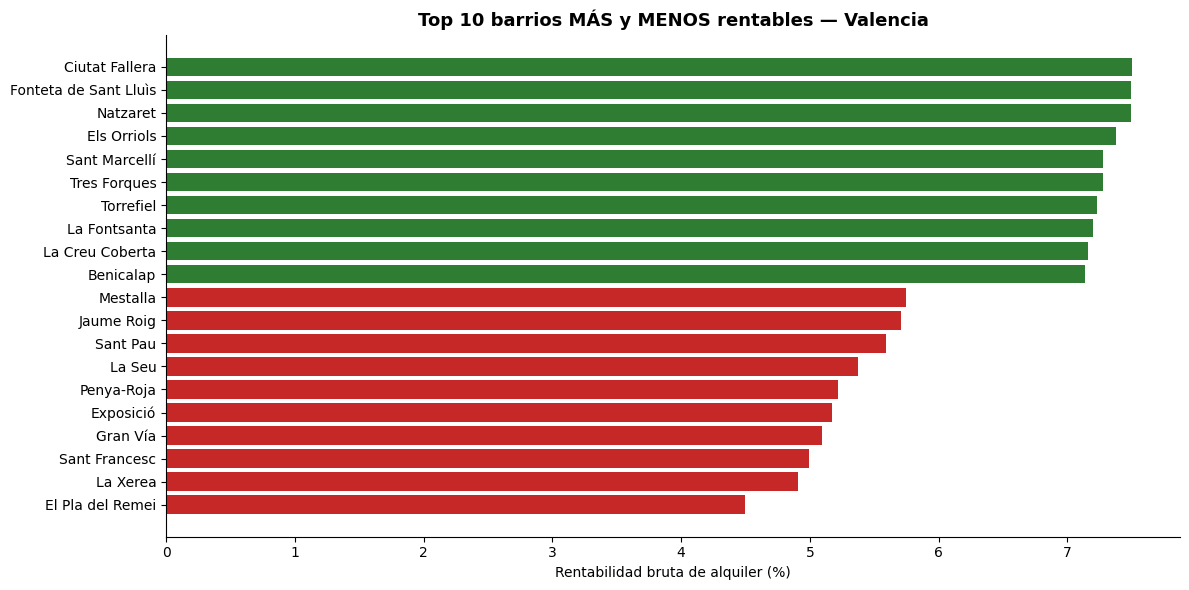

✅ Gráfico 1 guardado


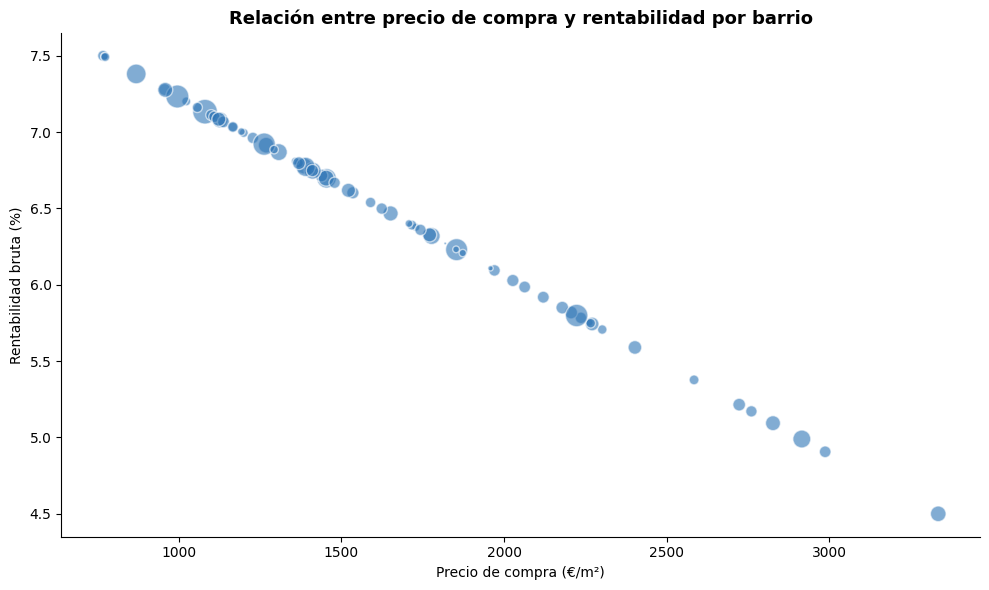

✅ Gráfico 2 guardado


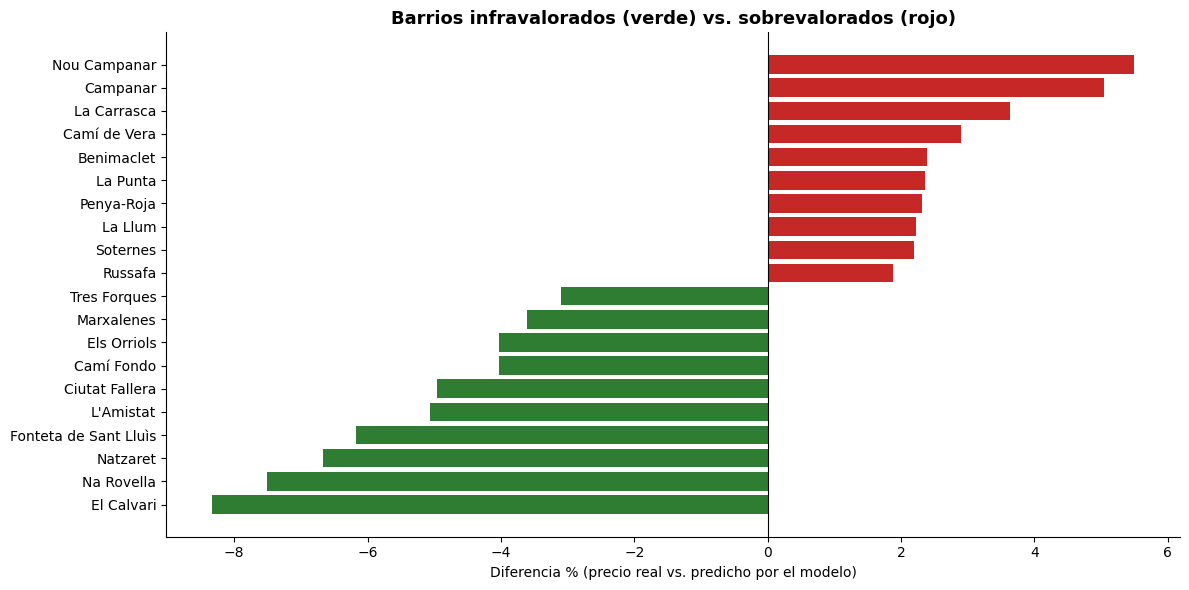

✅ Gráfico 3 guardado


In [19]:
# ── BLOQUE 12 — Gráficos estáticos para el README ──

# Gráfico 1: Top 10 barrios más rentables vs menos rentables
fig, ax = plt.subplots(figsize=(12, 6))
top_bottom = pd.concat([ranking.head(10), ranking.tail(10)])
colors_bar = ['#2E7D32']*10 + ['#C62828']*10
ax.barh(top_bottom['LOCATIONNAME'], top_bottom['yield_bruto_pct'], color=colors_bar)
ax.set_xlabel('Rentabilidad bruta de alquiler (%)')
ax.set_title('Top 10 barrios MÁS y MENOS rentables — Valencia', fontsize=13, fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('grafico1_rentabilidad_barrios.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gráfico 1 guardado")

# Gráfico 2: Precio de compra vs rentabilidad (dispersión)
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(compra_barrio['precio_compra_m2'], compra_barrio['yield_bruto_pct'],
          s=compra_barrio['n_anuncios']/5, alpha=0.6, color='#2E75B6', edgecolor='white')
ax.set_xlabel('Precio de compra (€/m²)')
ax.set_ylabel('Rentabilidad bruta (%)')
ax.set_title('Relación entre precio de compra y rentabilidad por barrio', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('grafico2_precio_vs_rentabilidad.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gráfico 2 guardado")

# Gráfico 3: Sobre/infravaloración top 10
fig, ax = plt.subplots(figsize=(12, 6))
val_sorted = valoracion_barrio.sort_values('diferencia_pct_media')
top_val = pd.concat([val_sorted.head(10), val_sorted.tail(10)])
colors_val = ['#2E7D32' if x < 0 else '#C62828' for x in top_val['diferencia_pct_media']]
ax.barh(top_val['LOCATIONNAME'], top_val['diferencia_pct_media'], color=colors_val)
ax.set_xlabel('Diferencia % (precio real vs. predicho por el modelo)')
ax.set_title('Barrios infravalorados (verde) vs. sobrevalorados (rojo)', fontsize=13, fontweight='bold')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('grafico3_sobrevaloracion.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gráfico 3 guardado")

In [20]:
# ── BLOQUE 13 — Exportar dataset final para Power BI ──

# Unimos todo lo que calculamos: precio, alquiler estimado, yield y valoración
export_powerbi = compra_barrio.merge(
    valoracion_barrio[['LOCATIONNAME', 'diferencia_pct_media']],
    on='LOCATIONNAME', how='left'
)

# Agregamos una columna de distrito para poder filtrar en Power BI (si está disponible)
export_powerbi = export_powerbi.rename(columns={
    'LOCATIONNAME': 'Barrio',
    'precio_compra_m2': 'Precio_Compra_m2',
    'n_anuncios': 'N_Anuncios',
    'alquiler_m2_mes_est': 'Alquiler_Estimado_m2_Mes',
    'yield_bruto_pct': 'Rentabilidad_Pct',
    'diferencia_pct_media': 'Sobre_Infravaloracion_Pct'
})

# Seleccionamos y ordenamos las columnas finales
columnas_finales = ['Barrio', 'Precio_Compra_m2', 'Alquiler_Estimado_m2_Mes',
                    'Rentabilidad_Pct', 'Sobre_Infravaloracion_Pct', 'N_Anuncios']
export_powerbi = export_powerbi[columnas_finales].round(2)

# Exportamos a CSV
export_powerbi.to_csv('valencia_inversion_powerbi.csv', index=False, encoding='utf-8-sig')

print(f"✅ Archivo exportado: {len(export_powerbi)} barrios")
print(f"\nColumnas: {list(export_powerbi.columns)}")
print(f"\nPrimeras 5 filas:")
print(export_powerbi.head().to_string(index=False))

✅ Archivo exportado: 73 barrios

Columnas: ['Barrio', 'Precio_Compra_m2', 'Alquiler_Estimado_m2_Mes', 'Rentabilidad_Pct', 'Sobre_Infravaloracion_Pct', 'N_Anuncios']

Primeras 5 filas:
          Barrio  Precio_Compra_m2  Alquiler_Estimado_m2_Mes  Rentabilidad_Pct  Sobre_Infravaloracion_Pct  N_Anuncios
           Aiora           1385.08                      7.82              6.78                      -1.96         666
          Albors           1589.74                      8.66              6.54                      -2.15         284
     Arrancapins           1854.17                      9.63              6.23                      -0.84        1267
Barrio de Favara           1166.67                      6.84              7.03                       0.34         227
       Benicalap           1081.08                      6.43              7.13                      -2.61        1581


In [21]:
import os
print(os.getcwd())
print(os.path.exists('valencia_inversion_powerbi.csv'))
print(os.listdir('.'))

/Users/lucasespinosa/Documents/proyecto3-churn-analysis/notebooks
True
['mapa_rentabilidad_valencia_v2.html', '.DS_Store', 'grafico3_sobrevaloracion.png', 'grafico1_rentabilidad_barrios.png', 'grafico2_precio_vs_rentabilidad.png', 'valencia_inversion_powerbi.csv', '.ipynb_checkpoints', 'proyecto5_inmobiliario_valencia.ipynb', 'mapa_rentabilidad_valencia.html', 'analisis_churn.ipynb']


In [22]:
# ── BLOQUE 14 — Re-exportar CSV con separador decimal de España (coma) ──

export_powerbi.to_csv('valencia_inversion_powerbi_es.csv', index=False, 
                       encoding='utf-8-sig', decimal=',', sep=';')

print("✅ Archivo exportado con formato decimal español (coma)")
print(export_powerbi.head())

✅ Archivo exportado con formato decimal español (coma)
             Barrio  Precio_Compra_m2  Alquiler_Estimado_m2_Mes  \
0             Aiora           1385.08                      7.82   
1            Albors           1589.74                      8.66   
2       Arrancapins           1854.17                      9.63   
3  Barrio de Favara           1166.67                      6.84   
4         Benicalap           1081.08                      6.43   

   Rentabilidad_Pct  Sobre_Infravaloracion_Pct  N_Anuncios  
0              6.78                      -1.96         666  
1              6.54                      -2.15         284  
2              6.23                      -0.84        1267  
3              7.03                       0.34         227  
4              7.13                      -2.61        1581  
